# ch02_4. MNIST 예측 오류 분석

## 개요

- 저장된 Checkpoint(체크포인트, 모델 저장 파일)를 불러옵니다.
- 전체 정확도와 오답률을 확인합니다.

## 공통 설정

데이터·모델·이미지 폴더 위치를 지정합니다.

In [1]:
from pathlib import Path

DATA_DIR = Path("data")
MODEL_DIR = Path("models")
PNG_DIR = Path("png")

DATA_DIR.mkdir(exist_ok=True)

MODEL_DIR.mkdir(exist_ok=True)
PNG_DIR.mkdir(exist_ok=True)

print("데이터 폴더:", DATA_DIR)
print("모델 폴더  :", MODEL_DIR)
print("이미지 폴더:", PNG_DIR)


데이터 폴더: data
모델 폴더  : models
이미지 폴더: png


## 공통 import

In [2]:
import io
from pathlib import Path
import numpy as np
import torch
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

### 1) 실행 장치 확인

```text
저장된 MLP Checkpoint 불러오기
→ 같은 MLP 구조와 정규화 복원
→ MNIST 테스트 데이터 예측
→ 전체 정확도와 오답률
→ 오분류 이미지 관찰
→ 혼동행렬
→ 숫자별 정확도
→ 자주 혼동하는 숫자쌍
→ 높은 확신도의 오답
→ 직접 그린 숫자 예측
```

 모델을 다시 학습하거나 선택하지 않습니다.

 검증 데이터로 선택한 모델의 **테스트 결과를 자세히 분석**합니다.

같은 CPU 또는 GPU 환경을 사용합니다.

In [3]:
RANDOM_SEED = 42

torch.manual_seed(RANDOM_SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("사용 장치:", device)

사용 장치: cuda


### 2) 모델 불러오기

저장된 파일 이름:

```text
ch02_3_best_mnist_mlp.pt
```

새 런타임이라면 저장해 둔 Checkpoint를 업로드합니다.

In [4]:
checkpoint_path = MODEL_DIR / "ch02_3_best_mnist_mlp.pt"

if not checkpoint_path.exists():
    raise FileNotFoundError(
        f"{checkpoint_path.name} 파일이 없습니다. "
        "저장된 MNIST MLP Checkpoint를 준비해 주세요."
    )

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

print("저장된 모델:", checkpoint["model_name"])

print(
    "Dropout 비율:",
    checkpoint["dropout_probability"]
)

저장된 모델: 기본 MLP
Dropout 비율: 0.0


### 3) 모델 구성

같은 MLP 구조를 `nn.Sequential`로 다시 만듭니다.

```text
Flatten
→ Linear(784, 512)
→ ReLU
→ Dropout
→ Linear(512, 256)
→ ReLU
→ Dropout
→ Linear(256, 10)
```

Checkpoint에 저장된 Dropout 비율과 가중치를 적용합니다.

In [5]:
def make_model(dropout_probability):
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(28 * 28, 512),
        nn.ReLU(),
        nn.Dropout(dropout_probability),
        nn.Linear(512, 256),
        nn.ReLU(),
        nn.Dropout(dropout_probability),
        nn.Linear(256, 10)
    )

model = make_model(
    checkpoint["dropout_probability"]
).to(device)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

normalization_mean = checkpoint[
    "normalization_mean"
][0]

normalization_std = checkpoint[
    "normalization_std"
][0]

print(model)

print()

print("정규화 평균:", normalization_mean)

print("정규화 표준편차:", normalization_std)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=512, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.0, inplace=False)
  (4): Linear(in_features=512, out_features=256, bias=True)
  (5): ReLU()
  (6): Dropout(p=0.0, inplace=False)
  (7): Linear(in_features=256, out_features=10, bias=True)
)

정규화 평균: 0.1307
정규화 표준편차: 0.3081


### 4) DataLoader 준비

학습할 때 사용한 평균과 표준편차를 테스트 데이터에도 동일하게 적용합니다.

```text
ToTensor
→ Normalize
→ DataLoader
```

In [6]:
test_transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize(
            (normalization_mean,),
            (normalization_std,)
        )
    ]
)

test_dataset = datasets.MNIST(
    root=str(DATA_DIR / "torchvision"),
    train=False,
    transform=test_transform,
    download=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False
)

print("테스트 데이터:", len(test_dataset))

테스트 데이터: 10000


### 5) 데이터 구조 확인

분석할 때 모델을 반복 실행하지 않도록 다음 결과를 한 번에 모읍니다.

- 정규화된 테스트 이미지
- 실제 정답
- 클래스별 로짓
- 클래스별 확률
- 최종 예측 숫자
- 가장 높은 예측 확률

In [7]:
image_batches = []

label_batches = []

logit_batches = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        logits = model(
            images.to(device)
        ).cpu()

        image_batches.append(
            images.cpu()
        )

        label_batches.append(
            labels.cpu()
        )

        logit_batches.append(
            logits
        )

all_images = torch.cat(
    image_batches
)

all_labels = torch.cat(
    label_batches
)

all_logits = torch.cat(
    logit_batches
)

all_probabilities = torch.softmax(
    all_logits,
    dim=1
)

all_confidences, all_predictions = (
    all_probabilities.max(dim=1)
)

print("이미지 shape:", all_images.shape)

print("정답 shape:", all_labels.shape)

print("로짓 shape:", all_logits.shape)

이미지 shape: torch.Size([10000, 1, 28, 28])
정답 shape: torch.Size([10000])
로짓 shape: torch.Size([10000, 10])


### 6) 테스트 성능 확인

- 정확도: 전체 이미지 중 맞힌 비율
- 오답률: 전체 이미지 중 틀린 비율

정확도가 높아도 어떤 숫자에서 약한지는 알 수 없습니다.
이제부터 오답의 위치와 유형을 자세히 확인합니다.

In [8]:
correct_mask = (
    all_predictions == all_labels
)

wrong_mask = ~correct_mask

correct_count = correct_mask.sum().item()

wrong_count = wrong_mask.sum().item()

accuracy = (
    correct_count / len(all_labels)
)

error_rate = (
    wrong_count / len(all_labels)
)

print(f"전체 정확도: {accuracy:.4f}")

print(f"오답률: {error_rate:.4f}")

print(
    f"정답 이미지: {correct_count:,}개"
)

print(
    f"오답 이미지: {wrong_count:,}개"
)

if "test_accuracy" in checkpoint:
    print()
    print(
        "Checkpoint 저장 정확도:",
        f"{checkpoint['test_accuracy']:.4f}"
    )

전체 정확도: 0.9618
오답률: 0.0382
정답 이미지: 9,618개
오답 이미지: 382개

Checkpoint 저장 정확도: 0.9618


### 7) 결과 시각화

가장 높은 확률의 숫자 하나만 보지 않고, 상위 세 숫자를 함께 확인합니다.

모델이 어떤 숫자 사이에서 고민했는지 알 수 있습니다.

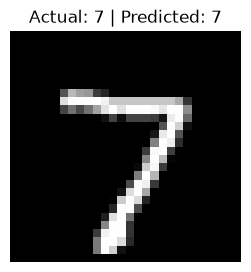

상위 3개 예측


In [9]:
sample_index = 0

sample_image = all_images[
    sample_index
]

sample_label = all_labels[
    sample_index
].item()

sample_probabilities = all_probabilities[
    sample_index
]

top_probabilities, top_classes = torch.topk(
    sample_probabilities,
    k=3
)

display_image = (
    sample_image * normalization_std
    + normalization_mean
).clamp(0, 1)

plt.figure(figsize=(3, 3))

plt.imshow(
    display_image.squeeze(),
    cmap="gray"
)

plt.title(
    f"Actual: {sample_label} | "
    f"Predicted: {top_classes[0].item()}"
)

plt.axis("off")

plt.show()

print("상위 3개 예측")

### 8) Top-k 확률 출력

In [10]:
for class_number, probability in zip(
    top_classes,
    top_probabilities
):
    print(
        f"숫자 {class_number.item()}: "
        f"{probability.item():.4f}"
    )

숫자 7: 1.0000
숫자 3: 0.0000
숫자 2: 0.0000


### 9) 오분류 이미지만 추출

Boolean Mask(불리언 마스크, 참·거짓 조건 선택)를 이용해 틀린 이미지만 모읍니다.

관찰할 내용:

- 사람이 보기에도 모호한가?
- 숫자가 중앙에서 벗어났는가?
- 획이 끊겼거나 지나치게 가는가?
- 다른 숫자와 비슷한 형태인가?

In [11]:
wrong_images = all_images[
    wrong_mask
]

wrong_labels = all_labels[
    wrong_mask
]

wrong_predictions = all_predictions[
    wrong_mask
]

wrong_confidences = all_confidences[
    wrong_mask
]

print("오답 이미지 shape:", wrong_images.shape)

오답 이미지 shape: torch.Size([382, 1, 28, 28])


### 10) 오분류 데이터 확인

처음 나타난 오답 12개를 확인합니다.

- `A`: 실제 숫자
- `P`: 예측 숫자
- `C`: 예측 확률

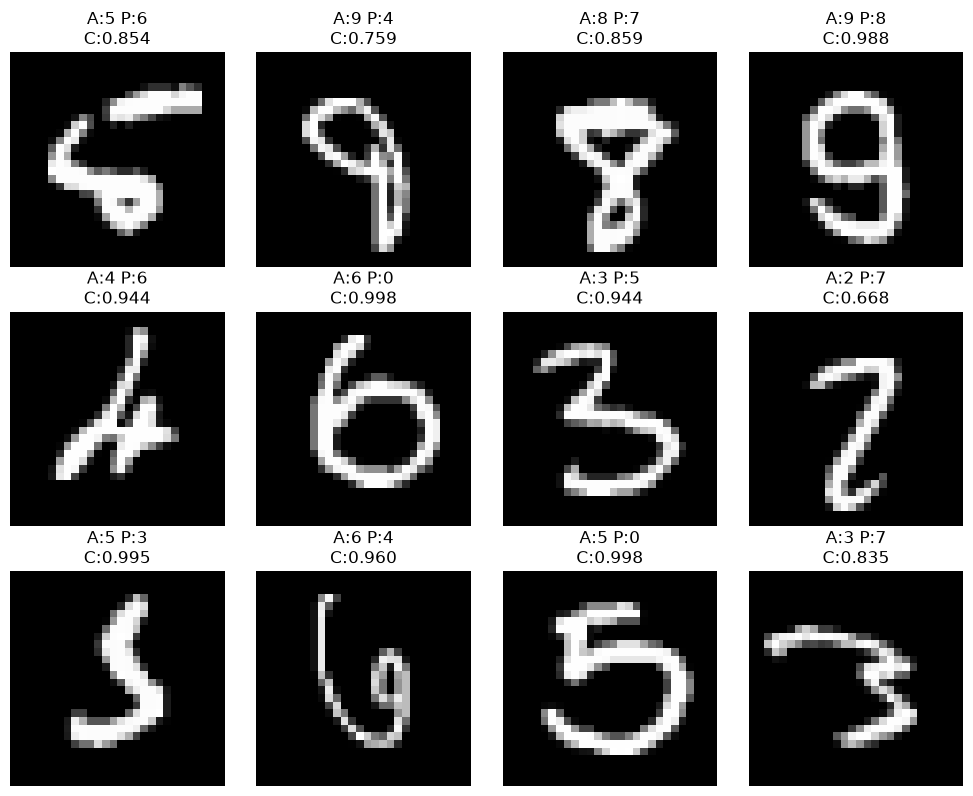

In [12]:
number_of_examples = min(
    12,
    len(wrong_images)
)

plt.figure(figsize=(10, 8))

for index in range(number_of_examples):
    display_image = (
        wrong_images[index]
        * normalization_std
        + normalization_mean
    ).clamp(0, 1)

    plt.subplot(3, 4, index + 1)

    plt.imshow(
        display_image.squeeze(),
        cmap="gray"
    )

    plt.title(
        f"A:{wrong_labels[index].item()} "
        f"P:{wrong_predictions[index].item()}\n"
        f"C:{wrong_confidences[index].item():.3f}"
    )

    plt.axis("off")

plt.tight_layout()

plt.show()

### 11) Confusion Matrix 준비

다중분류 혼동행렬의 구조:

```text
행: 실제 숫자
열: 예측 숫자
대각선: 올바른 예측
대각선 밖: 잘못된 예측
```

대각선 밖의 큰 값은 모델이 자주 혼동하는 숫자 관계입니다.

In [13]:
confusion_matrix = torch.zeros(
    10,
    10,
    dtype=torch.int64
)

### 12) Confusion Matrix 계산

In [14]:
for actual, predicted in zip(
    all_labels,
    all_predictions
):
    confusion_matrix[
        actual,
        predicted
    ] += 1

### 13) Confusion Matrix 시각화

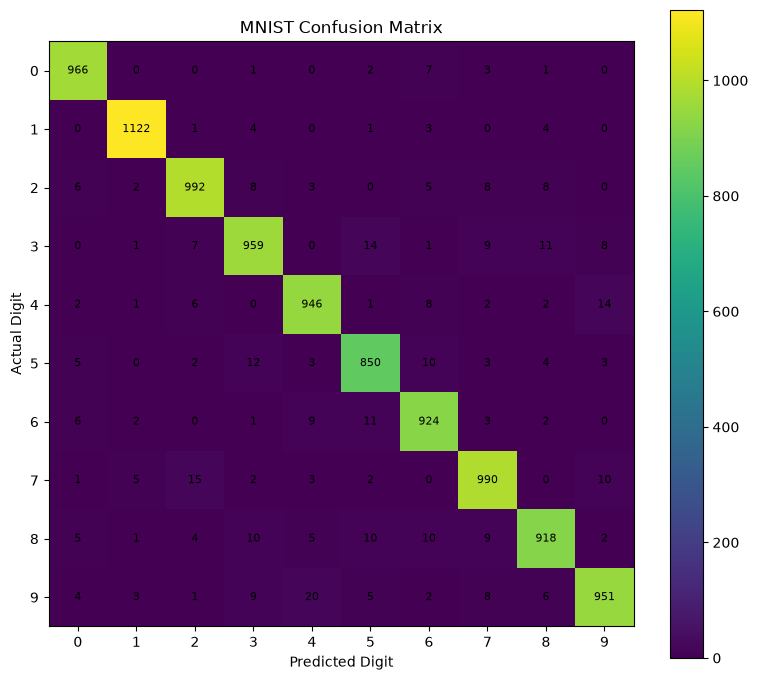

In [15]:
plt.figure(figsize=(8, 7))

plt.imshow(
    confusion_matrix.numpy()
)

plt.xticks(range(10))

plt.yticks(range(10))

plt.xlabel("Predicted Digit")

plt.ylabel("Actual Digit")

plt.title("MNIST Confusion Matrix")

for row in range(10):
    for column in range(10):
        plt.text(
            column,
            row,
            int(confusion_matrix[row, column]),
            ha="center",
            va="center",
            fontsize=8
        )

plt.colorbar()

plt.tight_layout()

plt.show()

### 14) 모델 구성

숫자별 정확도는 혼동행렬의 각 행에서 계산할 수 있습니다.

```text
숫자별 정확도
→ 해당 숫자를 맞힌 개수
÷ 해당 숫자의 전체 개수
```

전체 정확도만으로는 알 수 없었던 약한 숫자를 찾을 수 있습니다.

In [16]:
class_correct = confusion_matrix.diag()

class_total = confusion_matrix.sum(
    dim=1
)

class_accuracy = (
    class_correct.float()
    / class_total
)

for digit in range(10):
    print(
        f"숫자 {digit} | "
        f"정확도 {class_accuracy[digit].item():.4f} | "
        f"{class_correct[digit].item()}"
        f"/{class_total[digit].item()}"
    )

lowest_class = torch.argmin(
    class_accuracy
).item()

highest_class = torch.argmax(
    class_accuracy
).item()

print()

print("가장 낮은 정확도의 숫자:", lowest_class)

print("가장 높은 정확도의 숫자:", highest_class)

숫자 0 | 정확도 0.9857 | 966/980
숫자 1 | 정확도 0.9885 | 1122/1135
숫자 2 | 정확도 0.9612 | 992/1032
숫자 3 | 정확도 0.9495 | 959/1010
숫자 4 | 정확도 0.9633 | 946/982
숫자 5 | 정확도 0.9529 | 850/892
숫자 6 | 정확도 0.9645 | 924/958
숫자 7 | 정확도 0.9630 | 990/1028
숫자 8 | 정확도 0.9425 | 918/974
숫자 9 | 정확도 0.9425 | 951/1009

가장 낮은 정확도의 숫자: 8
가장 높은 정확도의 숫자: 1


### 15) 클래스별 정확도 확인

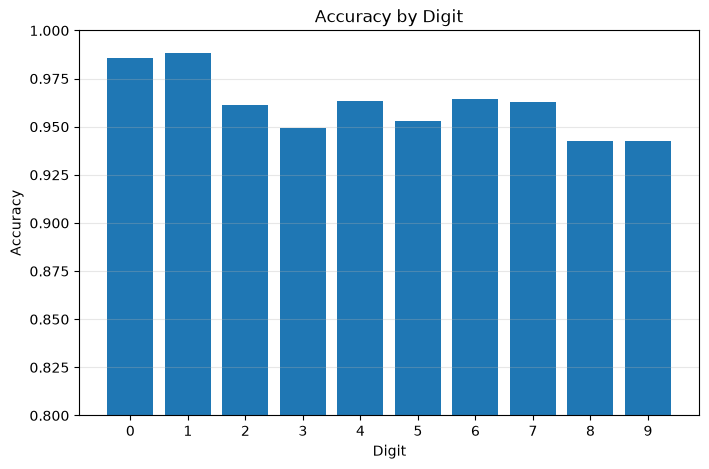

In [17]:
plt.figure(figsize=(8, 5))

plt.bar(
    range(10),
    class_accuracy.numpy()
)

plt.xticks(range(10))

plt.ylim(0.8, 1.0)

plt.xlabel("Digit")

plt.ylabel("Accuracy")

plt.title("Accuracy by Digit")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

### 16) 주요 오분류 관계 확인

혼동행렬의 대각선은 정답이므로 0으로 바꾼 뒤, 대각선 밖에서 큰 값 다섯 개를 찾습니다.

방향이 중요합니다.

```text
실제 4 → 예측 9
```

위 관계와 다음 관계는 서로 다른 오류입니다.

```text
실제 9 → 예측 4
```

In [18]:
wrong_confusion = confusion_matrix.clone()

wrong_confusion.fill_diagonal_(0)

top_counts, top_positions = torch.topk(
    wrong_confusion.flatten(),
    k=5
)

print("가장 자주 발생한 오분류 관계")

for count, position in zip(
    top_counts,
    top_positions
):
    actual = (
        position // 10
    ).item()

    predicted = (
        position % 10
    ).item()

    print(
        f"실제 {actual} → 예측 {predicted}: "
        f"{count.item()}개"
    )

가장 자주 발생한 오분류 관계
실제 9 → 예측 4: 20개
실제 7 → 예측 2: 15개
실제 3 → 예측 5: 14개
실제 4 → 예측 9: 14개
실제 5 → 예측 3: 12개


### 17) 결과 시각화

가장 많이 발생한 오분류 관계의 실제 이미지를 확인합니다.

숫자 모양의 공통점을 찾아 모델이 왜 혼동했는지 추정합니다.

실제 9 → 예측 4


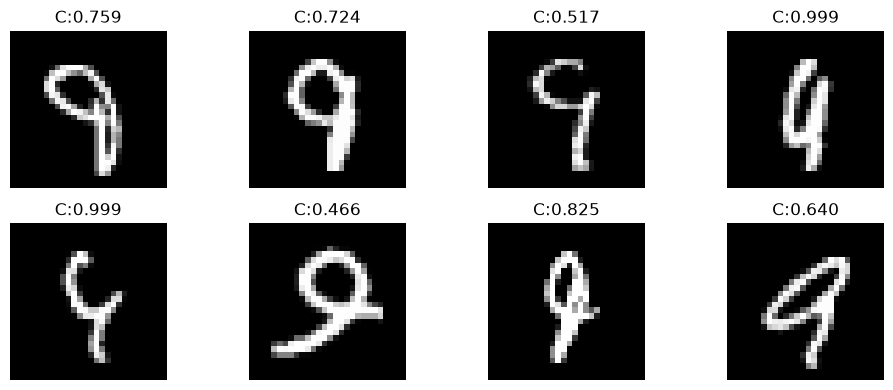

In [19]:
most_confused_position = top_positions[0]

confused_actual = (
    most_confused_position // 10
).item()

confused_predicted = (
    most_confused_position % 10
).item()

pair_mask = (
    (all_labels == confused_actual)
    & (all_predictions == confused_predicted)
)

pair_images = all_images[
    pair_mask
]

pair_confidences = all_confidences[
    pair_mask
]

number_of_pair_examples = min(
    8,
    len(pair_images)
)

print(
    f"실제 {confused_actual} → "
    f"예측 {confused_predicted}"
)

plt.figure(figsize=(10, 4))

for index in range(
    number_of_pair_examples
):
    display_image = (
        pair_images[index]
        * normalization_std
        + normalization_mean
    ).clamp(0, 1)

    plt.subplot(
        2,
        4,
        index + 1
    )

    plt.imshow(
        display_image.squeeze(),
        cmap="gray"
    )

    plt.title(
        f"C:{pair_confidences[index].item():.3f}"
    )

    plt.axis("off")

plt.tight_layout()

plt.show()

### 18) 데이터 전처리

Confidence(컨피던스, 모델이 선택한 클래스의 확률)를 비교합니다.

- 정답의 평균 확신도
- 오답의 평균 확신도

오답의 확률이 높더라도 실제 정답이라는 뜻은 아닙니다.

In [20]:
correct_confidences = all_confidences[
    correct_mask
]

print(
    "정답 평균 확신도:",
    f"{correct_confidences.mean().item():.4f}"
)

print(
    "오답 평균 확신도:",
    f"{wrong_confidences.mean().item():.4f}"
)

정답 평균 확신도: 0.9913
오답 평균 확신도: 0.8203


### 19) 오분류 데이터 확인

모델이 틀리면서도 높은 확률을 출력한 이미지를 확인합니다.

이런 사례는 모델의 확률을 그대로 신뢰하면 안 되는 이유를 보여 줍니다.

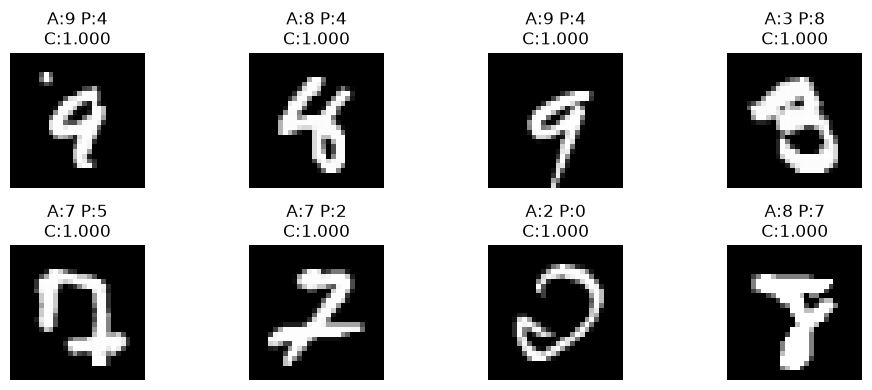

In [21]:
high_confidence_values, high_confidence_indices = (
    torch.topk(
        wrong_confidences,
        k=min(8, len(wrong_confidences))
    )
)

plt.figure(figsize=(10, 4))

for plot_index, wrong_index in enumerate(
    high_confidence_indices
):
    display_image = (
        wrong_images[wrong_index]
        * normalization_std
        + normalization_mean
    ).clamp(0, 1)

    plt.subplot(
        2,
        4,
        plot_index + 1
    )

    plt.imshow(
        display_image.squeeze(),
        cmap="gray"
    )

    plt.title(
        f"A:{wrong_labels[wrong_index].item()} "
        f"P:{wrong_predictions[wrong_index].item()}\n"
        f"C:{high_confidence_values[plot_index].item():.3f}"
    )

    plt.axis("off")

plt.tight_layout()

plt.show()

### 20) 데이터 전처리 설정

일반적인 그림과 MNIST의 차이:

```text
일반 그림
흰 배경 + 검은 숫자

MNIST
검은 배경 + 밝은 숫자
```

필요한 전처리:

```text
흑백 변환
→ 필요하면 색상 반전
→ 숫자 영역 자르기
→ 비율을 유지하며 20×20 안에 맞추기
→ 28×28 검은 화면 중앙에 배치
→ Tensor 변환
→ 학습과 같은 정규화
```

단순히 28×28로 강제 변환하면 숫자의 비율이 찌그러질 수 있습니다.

In [22]:
def preprocess_digit_image(image):
    grayscale = image.convert("L")

    image_array = np.array(
        grayscale
    )

    # 흰 배경이면 MNIST처럼 반전
    if image_array.mean() > 127:
        image_array = 255 - image_array

    # 약한 배경 잡음 제거
    image_array[
        image_array < 30
    ] = 0

    foreground_y, foreground_x = np.where(
        image_array > 0
    )

    if len(foreground_x) == 0:
        raise ValueError(
            "숫자 영역을 찾지 못했습니다."
        )

    left = foreground_x.min()
    right = foreground_x.max() + 1
    top = foreground_y.min()
    bottom = foreground_y.max() + 1

    cropped = Image.fromarray(
        image_array[
            top:bottom,
            left:right
        ]
    )

    scale = 20 / max(
        cropped.size
    )

    resized_size = (
        max(1, round(cropped.width * scale)),
        max(1, round(cropped.height * scale))
    )

    resized = cropped.resize(
        resized_size,
        Image.Resampling.LANCZOS
    )

    canvas = Image.new(
        "L",
        (28, 28),
        0
    )

    paste_position = (
        (28 - resized.width) // 2,
        (28 - resized.height) // 2
    )

    canvas.paste(
        resized,
        paste_position
    )

    tensor = transforms.ToTensor()(
        canvas
    )

    normalized_tensor = transforms.Normalize(
        (normalization_mean,),
        (normalization_std,)
    )(tensor)

    return canvas, normalized_tensor.unsqueeze(0)

### 21) 결과 시각화

예제 정답: 7


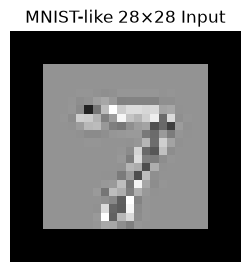

In [23]:
sample_tensor, sample_label = test_dataset[0]

original_image = transforms.ToPILImage()(
    sample_tensor
)

print("예제 정답:", sample_label)

processed_image, external_input = (
    preprocess_digit_image(
        original_image
    )
)

plt.figure(figsize=(3, 3))

plt.imshow(
    processed_image,
    cmap="gray"
)

plt.title("MNIST-like 28×28 Input")

plt.axis("off")

plt.show()

### 22) 평가 / 추론

In [24]:
model.eval()

with torch.no_grad():
    external_logits = model(
        external_input.to(device)
    )

    external_probabilities = torch.softmax(
        external_logits,
        dim=1
    ).cpu().squeeze(0)

top_probabilities, top_classes = torch.topk(
    external_probabilities,
    k=3
)

print("직접 그린 숫자의 상위 3개 예측")

for class_number, probability in zip(
    top_classes,
    top_probabilities
):
    print(
        f"숫자 {class_number.item()}: "
        f"{probability.item():.4f}"
    )

직접 그린 숫자의 상위 3개 예측
숫자 8: 0.9533
숫자 2: 0.0302
숫자 3: 0.0151


## 핵심 정리

- 모델을 다시 학습하지 않고 저장된 모델의 오류를 분석합니다.
- 숫자별 정확도는 전체 정확도에 가려진 약점을 보여 줍니다.
- 오류 분석 결과는 다음 모델 개선과 데이터 보강의 기준이 됩니다.